# Principal Component Analysis
**Name:** GUNDI RAHUL|  **Roll No:** CH.SC.U4CSE24211
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 11.4

## Exercise 1 - Why are Maggie's properties not selling?
Maggie's listings have many correlated attributes. PCA compresses them into a few components and shows which attributes travel together with `days_on_market`. Listing data is synthetic with realistic relationships.

Share unsold > 6 months: 0.045


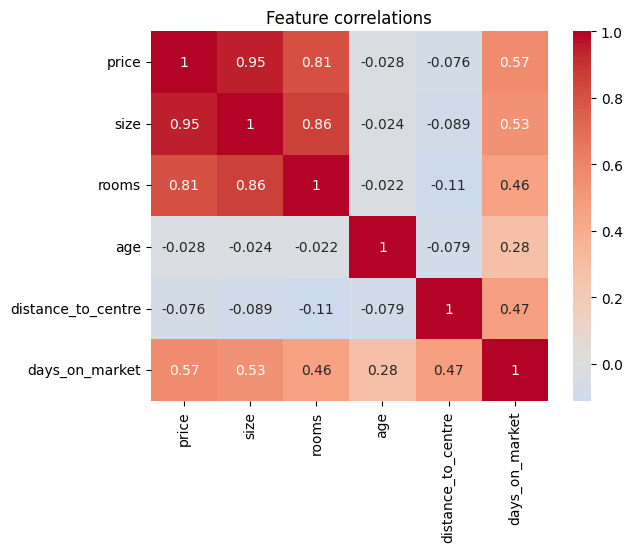

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

r = np.random.default_rng(262); n = 400
size = r.normal(150, 40, n); price = size * 3 + r.normal(0, 40, n) + 200
dist = r.normal(10, 4, n).clip(1); age = r.normal(25, 10, n).clip(0)
rooms = (size / 40 + r.normal(0, .5, n)).round().clip(1)
dom = (0.6 * (price - price.mean()) / price.std() + .5 * (dist - 10) / 4 + .3 * (age - 25) / 10 + r.normal(0, .5, n)) * 40 + 120
homes = pd.DataFrame(dict(price=price, size=size, rooms=rooms, age=age, distance_to_centre=dist, days_on_market=dom.clip(5)))
homes["unsold_6m"] = homes.days_on_market > 180
print("Share unsold > 6 months:", homes.unsold_6m.mean().round(3))
sns.heatmap(homes.drop(columns="unsold_6m").corr(), annot=True, cmap="coolwarm", center=0); plt.title("Feature correlations"); plt.show()

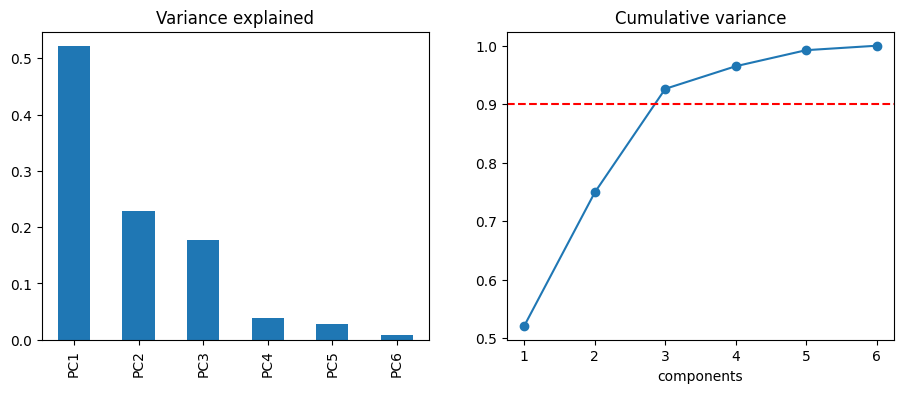

{'PC1': 0.521, 'PC2': 0.228, 'PC3': 0.177, 'PC4': 0.039, 'PC5': 0.027, 'PC6': 0.008}
Eigenvalues > 1 (Kaiser): 3


In [2]:
feat = ["price", "size", "rooms", "age", "distance_to_centre", "days_on_market"]
Z = StandardScaler().fit_transform(homes[feat]); pca = PCA().fit(Z)
ev = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(feat))])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ev.plot.bar(ax=ax[0]); ax[0].set_title("Variance explained")
ax[1].plot(range(1, 7), ev.cumsum().values, "o-"); ax[1].axhline(.9, ls="--", c="r"); ax[1].set(title="Cumulative variance", xlabel="components")
plt.show()
print(ev.round(3).to_dict()); print("Eigenvalues > 1 (Kaiser):", (pca.explained_variance_ > 1).sum())

                      PC1    PC2    PC3
price               0.539 -0.119 -0.041
size                0.542 -0.148 -0.036
rooms               0.507 -0.182 -0.024
age                 0.032  0.274  0.907
distance_to_centre  0.017  0.750 -0.409
days_on_market      0.396  0.541  0.079


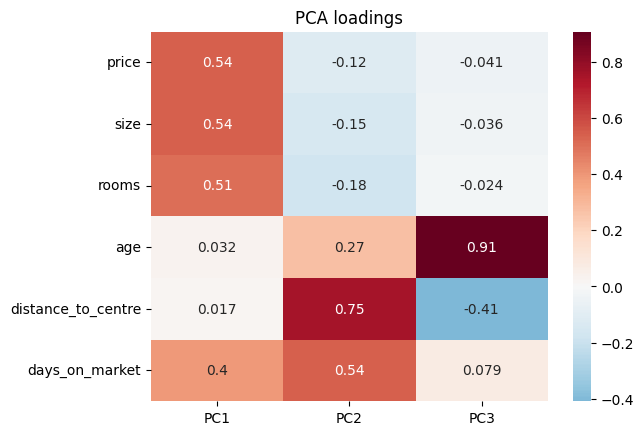

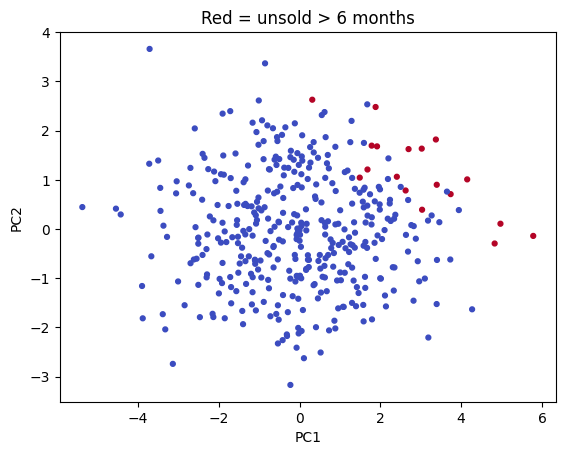

In [3]:
loadings = pd.DataFrame(pca.components_[:3].T, index=feat, columns=["PC1", "PC2", "PC3"]).round(3); print(loadings)
sns.heatmap(loadings, annot=True, cmap="RdBu_r", center=0); plt.title("PCA loadings"); plt.show()
scores = pca.transform(Z)
plt.scatter(scores[:, 0], scores[:, 1], c=homes.unsold_6m, cmap="coolwarm", s=12); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Red = unsold > 6 months"); plt.show()

In [4]:
comp = homes.groupby("unsold_6m")[feat].mean().T.round(1); comp["% higher"] = ((comp[True] / comp[False] - 1) * 100).round(1); comp

unsold_6m,False,True,% higher
price,644.3,836.0,29.8
size,149.1,206.5,38.5
rooms,3.7,5.1,37.8
age,24.1,27.6,14.5
distance_to_centre,10.0,13.2,32.0
days_on_market,117.5,193.7,64.9


**Insight for Maggie:** properties stuck on the market for 6+ months are systematically *larger, pricier (about 30% higher), farther from the centre and somewhat older*. Size and price move together, so they are over-priced for their location; price is the lever she can pull fastest.

## Exercise 2 - Which variable is the principal component?
The loadings table is given in the book. PCA components are linear combinations of variables, so the question is which variable dominates **PC1** (the component with most variance).

Largest |loading| per component: {'PC1': 'Arts', 'PC2': 'Health', 'PC3': 'Crime'}

PC1 ranking:
 Arts              0.985
Health            0.782
Transportation    0.585
Housing           0.544
Recreation        0.520
Education         0.394
Crime             0.365
Climate           0.190
Economy           0.142
Name: PC1, dtype: float64


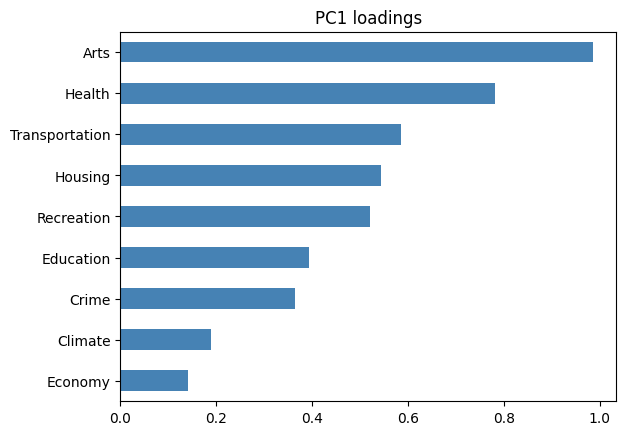

In [5]:
book = pd.DataFrame({"PC1": [.190, .544, .782, .365, .585, .394, .985, .520, .142],
                     "PC2": [.017, .020, -.605, .294, .085, -.273, .126, .402, .150],
                     "PC3": [.207, .204, .144, .585, .234, .027, -.111, .519, .239]},
                    index=["Climate", "Housing", "Health", "Crime", "Transportation", "Education", "Arts", "Recreation", "Economy"])
print("Largest |loading| per component:", book.abs().idxmax().to_dict())
print("\nPC1 ranking:\n", book.PC1.sort_values(ascending=False))
book.PC1.sort_values().plot.barh(color="steelblue"); plt.title("PC1 loadings"); plt.show()

**Answer:** on PC1 the strongest variable is **Arts (0.985)**, followed by Health (0.782). Health also drives PC2 (-0.605) and Crime drives PC3 (0.585).